# 02 · Manifold — principal-curve trajectory (full malignant manifold)

Jansky's malignant manifold is **non-branching**: a continuous noradrenergic
differentiation continuum, not a hub radiating to discrete subtypes and not an
adrenergic↔mesenchymal bifurcation (the mesenchymal arm is absent — MES scores sit
at baseline everywhere). The correct topology is a **principal curve** (ElPiGraph,
non-branching by construction) fit on the joint integrated embedding — **not** a
re-embedding. A PPT tree over-fits this compact continuum into many spurious
tips/forks whose count grows with node number (noise, not a Puram-style
bifurcation), confirming the curve is the right model. The curve is rooted at the
gastrulation/somitogenesis-high tip (developmental origin), pseudotime flows to the
neural-crest terminus, and the embedding is reoriented to house style (low
pseudotime left → high right). Because the developmental axis lies **diagonal** in
the raw embedding, orientation uses a **guarded pure rotation** (determinant +1, no
reflection; verified `corr(x, pseudotime) > 0`) rather than an axis swap.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Jansky2021_Neuroendocrine | category: Neuroendocrine


### Load processed manifold — keep the full malignant compartment
Cells stay on their *original joint embedding coordinates* — no re-embedding. The
raw UMAP aspect ratio is reported: a compact (near-isotropic) cloud is honest 2-D
geometry that a principal curve threads, not an elongated 1-D strip.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata.copy()
print('malignant manifold:', sub.shape[0], 'cells on the joint embedding')
xy = sub.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

malignant manifold: 27987 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.25


### Curve vs tree — confirm non-branching topology
A PPT tree is fit first as a control at several node counts: a genuine bifurcation
resolves a **stable** small number of tips/forks across resolutions (as Puram's
Mixed-hub bifurcation does). Here forks instead **proliferate with node count** —
the signature of a tree over-fit to a continuous cloud, i.e. no real branch. The
principal curve then gives a **fold-free** monotone backbone. A node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median
edge length) certifies the curve does not fold back on itself; `epg_mu=100` is
strong bending regularisation keeping the backbone smooth.

In [4]:
# control: PPT tree fork-count scales with node count -> no stable bifurcation
for N in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        tmp = sub.copy()
        scf.tl.tree(tmp, Nodes=N, use_rep='X_umap', method='ppt', ppt_sigma=1, ppt_lambda=1, seed=SEED, plot=False)
    Bt = np.asarray(tmp.uns['graph']['B'])
    print(f'PPT Nodes={N}: {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks')
del tmp
print('forks scale with node count -> over-fit continuum, no stable bifurcation')

PPT Nodes=15: 2 tips, 0 forks
PPT Nodes=20: 3 tips, 1 forks
PPT Nodes=30: 3 tips, 1 forks
forks scale with node count -> over-fit continuum, no stable bifurcation


In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'principal curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

principal curve: 2 tips, 0 forks | fold self-approach ratio = 3.00 (>1 = fold-free)


### Score embryonic modules and derive the root (data-driven)
The three developmental signatures (Gastrulation / Somitogenesis / Neural-crest)
are scored against the shared **union** control pool, then graph-smoothed to read
*geography* rather than single-cell dropout. The root is set to the curve tip where
Gast+pSom is highest and Crest lowest — the developmental origin.

In [6]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]

Gast: 74/81 genes present
pSom: 85/98 genes present
Crest: 98/104 genes present


In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0077 pSom=+0.0198 Crest=-0.0171
tip 2: Gast=+0.0039 pSom=+0.0178 Crest=-0.0131
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.435 p=0.0e+00
  pSom_sm: rho=-0.137 p=8.1e-118
  Crest_sm: rho=+0.359 p=0.0e+00


### Reorient to house style (pseudotime left → right) — guarded pure rotation
The developmental axis here is **diagonal** in the raw embedding, so an axis-swap
(as used where the axis is already near-horizontal/vertical) is insufficient. The
gradient direction of pseudotime in UMAP space is found by least squares, and the
cloud is rotated so that direction becomes +x. The transform is a **pure rotation
matrix** (determinant +1 by construction — never a reflection, which would silently
mirror the biology), with a 180° rotation applied if needed to place low pseudotime
on the left. The assertion confirms `corr(x_lin, pseudotime) > 0`.

In [8]:
xy = sub.obsm['X_umap'].astype(float); t = sub.obs['t'].values
xyc = xy - xy.mean(0)
b, *_ = np.linalg.lstsq(xyc, t - t.mean(), rcond=None)   # gradient dir of pseudotime
ang = np.arctan2(b[1], b[0])
c_, s_ = np.cos(-ang), np.sin(-ang)
Rot = np.array([[c_, -s_], [s_, c_]])                     # rotate grad-dir onto +x
assert np.isclose(np.linalg.det(Rot), 1.0), 'not a pure rotation'
xyr = xyc @ Rot.T
if np.corrcoef(xyr[:,0], t)[0,1] < 0:                     # 180 deg (still det +1)
    xyr = xyr @ np.array([[-1.,0.],[0.,-1.]]).T
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'guarded rotation: angle={np.degrees(ang):.1f} deg, det(R)=+1 (no reflection); corr(x_lin, pseudotime) = {r:+.2f}')

guarded rotation: angle=133.3 deg, det(R)=+1 (no reflection); corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


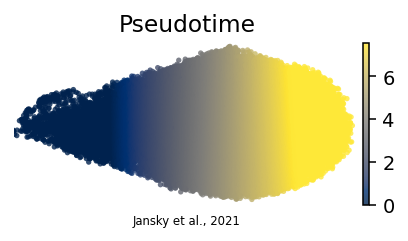

In [9]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Jansky et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')